<img src="https://complexsystemsintelligence.github.io/biztonsagkritikus-rendszerek/gyakorlat/assets/logo/pe-cimer-nevjel-fekvo-kek.png" alt="Pannon Egyetem – University of Pannonia" height="56">

[Megnyitás a Google Colabban](https://colab.research.google.com/github/ComplexSystemsIntelligence/biztonsagkritikus-rendszerek/blob/main/gyakorlat/notebookok/08_hibafa.ipynb) · *Biztonságkritikus rendszerek – gyakorlati útmutató* · © 2026 Abonyi János, Pannon Egyetem · kód: MIT, szöveg: CC BY-NC-SA 4.0

# 8. gyakorlat – hibafa: MOCUS, bináris döntési diagram, fontosság és bizonytalanság

A notebook a könyv 10. fejezetének ReaktorVéd-hibafáját elemzi: minimális vágatok a MOCUS-eljárással, pontos valószínűség Shannon-kifejtéssel (a bináris döntési diagram elvén), fontossági mértékek, végül Monte Carlo-bizonytalanságelemzés.

**Tanulási eredmények:** hibafa programozott elemzése; a ritkaesemény-közelítés és a pontos érték összevetése; a fontossági mértékek kiszámolása és értelmezése; a paraméterbizonytalanság terjedésének becslése.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
PE = {"kek": "#285780", "sotet": "#1B3A57", "kiemel": "#E07B39", "zold": "#3E8E63", "piros": "#B83A3A", "lila": "#7A5C99", "szurke": "#6B7280"}
plt.rcParams.update({"figure.figsize": (7.5, 4.2), "axes.grid": True, "grid.color": "#e6e9ee", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=list(PE.values())), "axes.formatter.use_locale": False})
def hu(x, sig=3):
    """Szám magyar formátumban (tizedesvessző, normálalak)."""
    if x == 0: return "0"
    e = int(np.floor(np.log10(abs(x))))
    if -2 <= e < 5: return f"{x:.{max(0, sig-1-e)}f}".replace(".", ",")
    return f"{x/10**e:.{sig-1}f}".replace(".", ",") + f"·10^{e}"


In [2]:
# A hibafa: kapuk (típus, bemenetek) és alapesemények (valószínűség). HEN: házesemény (1 = energiával működtetett szelepek)
def fa(HEN=1):
    G = {"TOP": ("AND", ["G2", "G3"]), "G2": ("OR", ["BE1", "E1TAP", "G4"]), "G3": ("OR", ["BE2", "E1TAP", "G4"]),
         "G4": ("OR", ["BE4", "E1TAP", "G5"]), "G5": ("AND", ["G6", "G7"]), "G6": ("OR", ["BE5", "E2TAP"]), "G7": ("OR", ["BE7", "E2TAP"])}
    if HEN: G["E1TAP"] = ("OR", ["BE3"]); G["E2TAP"] = ("OR", ["BE6"])
    else:   G["E1TAP"] = ("OR", []);      G["E2TAP"] = ("OR", [])      # üres VAGY = sosem következik be
    return G
q = {"BE1": 1.097e-2, "BE2": 1.097e-2, "BE3": 1e-3, "BE4": 5e-5, "BE5": 1.752e-3, "BE6": 1e-3, "BE7": 1.752e-3}

def minimalis(L):
    L = sorted({frozenset(c) for c in L}, key=len); ki = []
    for c in L:
        if not any(m <= c for m in ki): ki.append(c)
    return ki
def mocus(G, n="TOP"):
    if n not in G: return [frozenset([n])]
    tip, be = G[n]
    if tip == "OR":
        return minimalis([c for b in be for c in mocus(G, b)])
    vag = [frozenset()]
    for b in be:
        vag = minimalis([a | c for a in vag for c in mocus(G, b)])
    return vag
mcs = mocus(fa(1))
for c in sorted(mcs, key=lambda c: (len(c), sorted(c))):
    print(sorted(c), hu(np.prod([q[x] for x in c])))

['BE3'] 1,00·10^-3
['BE4'] 5,00·10^-5
['BE6'] 1,00·10^-3
['BE1', 'BE2'] 1,20·10^-4
['BE5', 'BE7'] 3,07·10^-6


In [3]:
def pontos(cuts, q, memo=None):
    """A csúcsesemény pontos valószínűsége Shannon-kifejtéssel (a BDD elve)."""
    memo = {} if memo is None else memo
    if any(len(c) == 0 for c in cuts): return 1.0
    if not cuts: return 0.0
    kulcs = frozenset(cuts)
    if kulcs in memo: return memo[kulcs]
    gyak = {}
    for c in cuts:
        for v in c: gyak[v] = gyak.get(v, 0) + 1
    x = max(gyak, key=gyak.get)
    egy = minimalis([c - {x} for c in cuts]); nulla = [c for c in cuts if x not in c]
    p = q[x]*pontos(egy, q, memo) + (1-q[x])*pontos(nulla, q, memo)
    memo[kulcs] = p; return p
Qk = [np.prod([q[x] for x in c]) for c in mcs]
print("ritkaesemény-közelítés:", hu(sum(Qk), 5))
print("felső korlát (MCUB):   ", hu(1 - np.prod([1-v for v in Qk]), 5))
print("pontos:                ", hu(pontos(mcs, q), 5))
print("energiamentesítéssel (HEN = 0):", hu(pontos(mocus(fa(0)), q), 4))

ritkaesemény-közelítés: 2,1734·10^-3
felső korlát (MCUB):    2,1721·10^-3
pontos:                 2,1721·10^-3
energiamentesítéssel (HEN = 0): 1,734·10^-4


## Fontossági mértékek

In [4]:
Q = pontos(mcs, q); rare = sum(Qk)
print(f"{'esemény':8s} {'Birnbaum':>10s} {'FV':>7s} {'RAW':>8s} {'RRW':>7s}")
for v in sorted(q):
    Q1 = pontos(mcs, {**q, v: 1.0}); Q0 = pontos(mcs, {**q, v: 0.0})
    fv = sum(Qc for c, Qc in zip(mcs, Qk) if v in c)/rare
    print(f"{v:8s} {Q1-Q0:10.3e} {fv:7.3f} {Q1/Q:8.1f} {Q/Q0:7.3f}")

esemény    Birnbaum      FV      RAW     RRW
BE1       1.095e-02   0.055      6.0   1.059
BE2       1.095e-02   0.055      6.0   1.059
BE3       9.988e-01   0.460    460.4   1.851
BE4       9.979e-01   0.023    460.4   1.024
BE5       1.748e-03   0.001      1.8   1.001
BE6       9.988e-01   0.460    460.4   1.851
BE7       1.748e-03   0.001      1.8   1.001


## Monte Carlo-bizonytalanság

Minden alapesemény valószínűsége lognormális, mediánja a pontbecslés, hibatényezője EF = 3 ($\sigma = \ln 3/1{,}645$).

pontbecslés: 2,17·10^-3  átlag: 2,75·10^-3  medián: 2,47·10^-3
90 %-os intervallum: 1,20·10^-3 – 5,28·10^-3


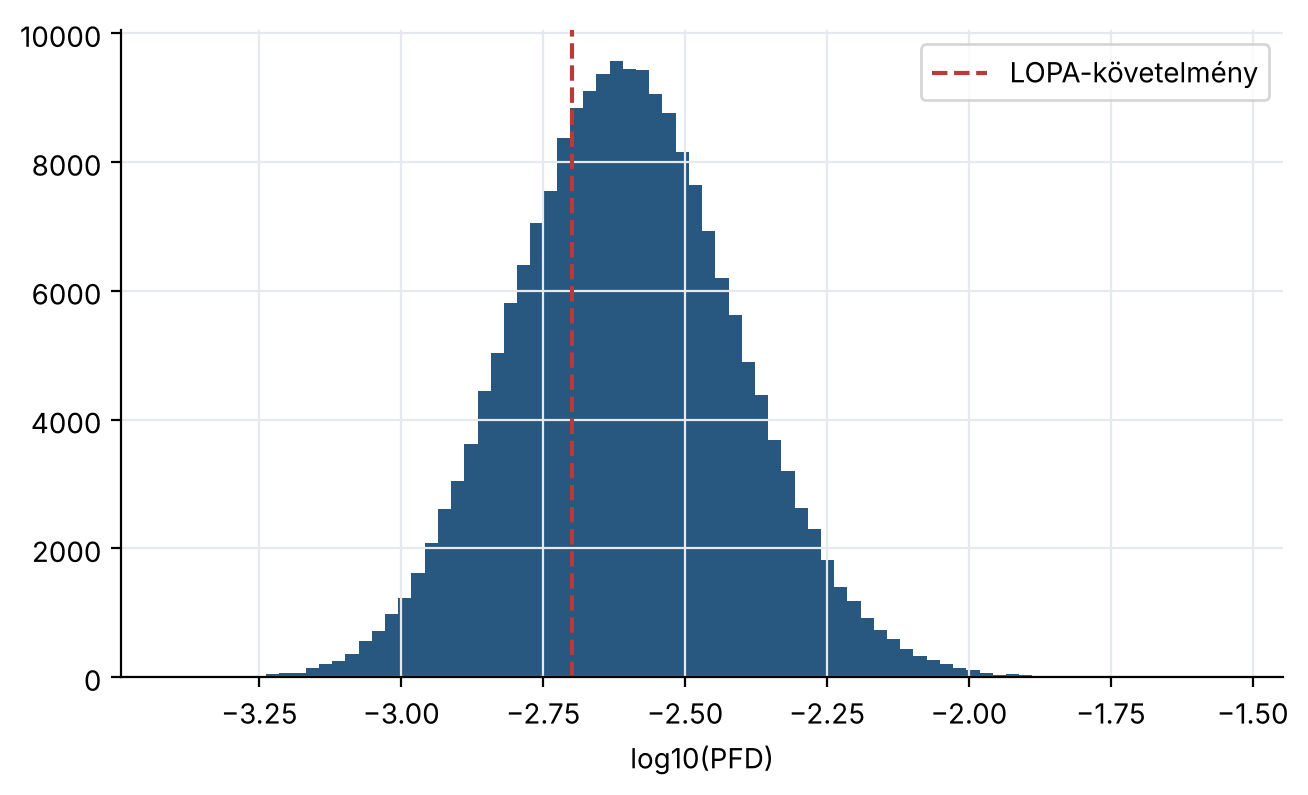

In [5]:
rng = np.random.default_rng(7); Nmc = 200000; sig = np.log(3)/1.645
minta = {v: q[v]*np.exp(sig*rng.standard_normal(Nmc)) for v in q}
top = np.zeros(Nmc)
for c in mcs:                 # ritkaesemény-közelítés mintánként (kis valószínűségeknél pontos)
    top += np.prod([minta[x] for x in c], axis=0)
print("pontbecslés:", hu(rare), " átlag:", hu(top.mean()), " medián:", hu(np.median(top)))
print("90 %-os intervallum:", hu(np.percentile(top, 5)), "–", hu(np.percentile(top, 95)))
plt.hist(np.log10(top), bins=80, color=PE["kek"]); plt.axvline(np.log10(2e-3), color=PE["piros"], ls="--", label="LOPA-követelmény")
plt.xlabel("log10(PFD)"); plt.legend(); plt.show()

**1. feladat.** Építsd be a közös okú meghibásodást (szelepek: β = 10%, távadók: β = 5%) az energiamentesítéses változatba, és ellenőrizd, hogy $1{,}335\cdot10^{-3}$ jön ki!

**2. feladat.** A fontossági mértékek alapján melyik egyetlen tervezési változtatás csökkentené leginkább a kockázatot az energiával működtetett változatban? Indokold a Fussell–Vesely- és az RRW-értékkel!

## Mintaprompt

*„Az alábbi hibafa minimális vágatait MOCUS-eljárással határoztam meg: … Ellenőrizd, hogy a vágatok valóban minimálisak-e, és hogy nem hiányzik-e közülük egy sem! Indokold lépésenként a Boole-algebrai átalakításokkal.”*